In [ ]:
from anomalouslib.data.DatasetGenerator import DatasetGenerator
from anomalouslib.analysis.DataAnalyzer import DataAnalyzer
from anomalouslib.models.model_handler import load_model
from anomalouslib.data.preprocessing import generate_classification_tensors
from anomalouslib.analysis.DataAnalyzer import DataAnalyzer
from anomalouslib.constants import trajectory_types_mapping
from sklearn.preprocessing import LabelEncoder

import matplotlib.pyplot as plt
import torch.nn.functional as F
import numpy as np
import torch

In [2]:
model, le = load_model("./TrajectoryTypeClassifier.pth")

In [3]:
def generate_classification_tensors(dataframe, parm_to_eval: str, le = LabelEncoder()):
    # dataframe = dataframe.drop(columns=['num_steps', 'attributes'])
    dataframe = dataframe.sample(frac=1).reset_index(drop=True)

    # Tractem les coordenades per aconseguir X_tensor
    coords_list = [np.stack([row[0], row[1]], axis=1) for row in dataframe['coords']]
    X = np.array(coords_list)  # Forma (n_samples, seq_length, 2)
    X_tensor = torch.tensor(X, dtype=torch.float32).permute(0, 2, 1)

    # Tractem les coordenades per aconseguir y_tensor
    labels = le.transform(dataframe["attributes"].apply(lambda x: x[parm_to_eval]))
    labels_tensor  = torch.tensor(labels, dtype=torch.long)
    y_tensor = F.one_hot(labels_tensor, num_classes=7).float()

    return X_tensor, y_tensor

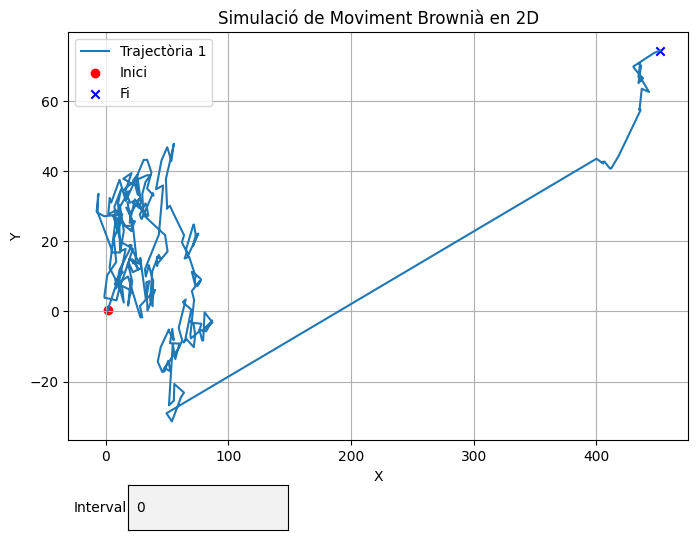

In [36]:
traj = DatasetGenerator(num_particules=1).generate_LevyWalks(num_passos=300, random_params=True)
DataAnalyzer(traj).mostrar_trajectories()

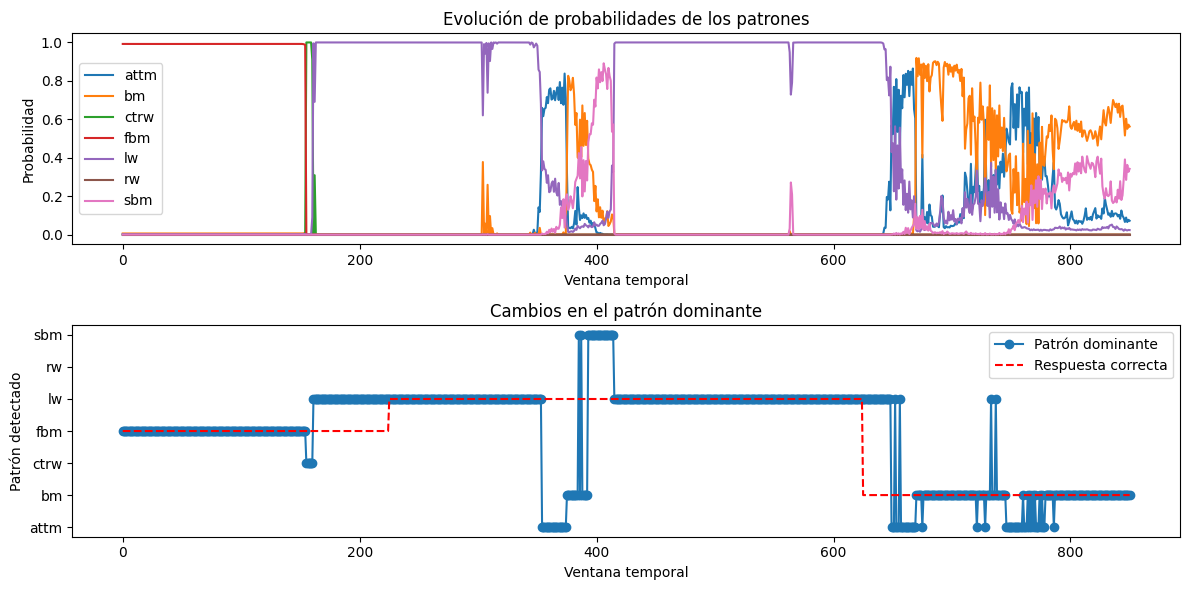

In [ ]:
def analyze_discrete_trajectory_patterns(model, traj, parm_to_eval, le, traj_pos=0, window_size=150):
    dataframe = traj.iloc[[traj_pos]].copy()
    dataframe = dataframe.sample(frac=1).reset_index(drop=True)

    # Tractem les coordenades per aconseguir X_tensor
    coords_list = [np.stack([row[0], row[1]], axis=1) for row in dataframe['coords']]
    X = np.array(coords_list)  # Forma (n_samples, seq_length, 2)
    X_tensor = torch.tensor(X, dtype=torch.float32).permute(0, 2, 1)

    params = dataframe["attributes"].apply(lambda x: x[parm_to_eval])[0]

    def get_correct_type(diccionario, valor):
        claves_ordenadas = sorted(diccionario.keys())
        for i in range(len(claves_ordenadas)):
            inicio = claves_ordenadas[i]
            fin = claves_ordenadas[i + 1] if i + 1 < len(claves_ordenadas) else float('inf')
            if inicio <= valor < fin:
                return diccionario[inicio]
        return None
    
    with torch.no_grad():
        out = model(X_tensor)
        predicted_class = torch.argmax(out, dim=1).item()

    X_unfolded = X_tensor.unfold(dimension=2, size=window_size, step=1)
    X_windows = X_unfolded.permute(2, 0, 1, 3)
    X_list = [x for x in X_windows]

    X_adjusted = []
    for window in X_list:
        start = window[:, :, 0].unsqueeze(-1)
        adjusted = window - start
        X_adjusted.append(adjusted)

    model.eval()
    outputs = []
    values = []
    with torch.no_grad():
        for x in X_adjusted:
            out = model(x)
            out = F.softmax(out, dim=1)
            predicted_class = torch.argmax(out, dim=1).item()
            array = out.numpy()[0]
            outputs.append(np.array(array))
            values.append(le.inverse_transform([predicted_class])[0])

    outputs = np.array(outputs)
    long_names = le.inverse_transform(np.arange(outputs.shape[1]))
    short_pattern_names = np.array([trajectory_types_mapping[long_name].__name__ for long_name in long_names])
    if outputs.size > 0:
        plt.figure(figsize=(12, 6))
        plt.subplot(2, 1, 1)
        for i in range(outputs.shape[1]):
            plt.plot(outputs[:, i], label=f'{short_pattern_names[i]}')
        plt.title('Evolución de probabilidades de los patrones')
        plt.xlabel('Ventana temporal')
        plt.ylabel('Probabilidad')
        plt.legend()

        plt.subplot(2, 1, 2)
        patron_dominante = np.argmax(outputs, axis=1)
        plt.plot(patron_dominante, 'o-', label='Patrón dominante')
        
        # Evaluar la clase correcta para cada ventana temporal
        correct_classes = []
        correct_labels = []
        correct_shorts = []
        for i in range(len(outputs)):
            # El valor de tiempo es el índice de la ventana
            current_label = get_correct_type(params, i+window_size//2)
            if current_label:
                correct_labels.append(current_label)
                correct_class = le.transform([current_label])[0]
                correct_classes.append(correct_class)
                correct_shorts.append(trajectory_types_mapping[current_label].__name__)
            else:
                correct_classes.append(None)
                correct_shorts.append(None)

        # Dibujar la línea de la respuesta correcta para cada ventana
        plt.plot(correct_classes, color='red', linestyle='--', label='Respuesta correcta')

        plt.title('Cambios en el patrón dominante')
        plt.xlabel('Ventana temporal')
        plt.ylabel('Patrón detectado')
        plt.yticks(np.arange(outputs.shape[1]), short_pattern_names)
        plt.legend()
        plt.tight_layout()
        plt.show()
    return outputs, values

outputs, values = analyze_trajectory_patterns(model, traj, "trajectory_type", le)


In [136]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# Generar dos trayectorias de tipos diferentes y concatenarlas
dg = DatasetGenerator(num_particules=1)
traj1 = dg.generate_FractionalBrownianMotion(num_passos=300, random_params=True)
traj2 = dg.generate_LevyWalks(num_passos=400, alpha=1.5, beta=0.75, speed=2)
traj3 = dg.generate_BrownianMotion(num_passos=300, sigma=3, delta_t=0.5)

# Concatenar las trayectorias
traj_concat = traj1.copy()
# Obtener el último valor de traj1
last_coords_traj1 = np.array(traj1.iloc[0]["coords"])
last_point = last_coords_traj1[:, -1]

# Obtener los valores de traj2 y sumarle el último punto de traj1
coords_traj2 = np.array(traj2.iloc[0]["coords"])
coords_traj2_shifted = coords_traj2 + last_point[:, None]

# Concatenar las coordenadas
coords_concat = np.concatenate([last_coords_traj1, coords_traj2_shifted], axis=1)

# Obtener el último valor de traj1
last_point2 = coords_concat[:, -1]

# Obtener los valores de traj3 y sumarle el último punto de traj2
coords_traj3 = np.array(traj3.iloc[0]["coords"])
coords_traj3_shifted = coords_traj3 + last_point2[:, None]

# Concatenar las coordenadas
coords_concat = np.concatenate([coords_concat, coords_traj3_shifted], axis=1)

# Actualizar el DataFrame concatenado
traj_concat.at[0, "coords"] = coords_concat.tolist()
traj_concat.at[0, "num_steps"] = coords_concat.shape[1]
# traj_concat.at[0, "trajectory_type"] = traj1.iloc[0]["trajectory_type"] + "+" + traj2.iloc[0]["trajectory_type"]
traj_concat.at[0, "attributes"] = {
    "trajectory_type": {
        0: "Fractional Brownian Motion",
        300: "Lévy Walk",
        700: "Brownian Motion"
    }
}
traj = traj_concat

c:\Users\jmass\Documents\GitHub\TFG GEINF\AnomalousLab\venv\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(
